# 03 · Multi-touch attribution

Five models on the same journeys: **last-click, first-click, linear, Markov chain (removal
effect) and Shapley value**, plus a Shapley variant to show how much the game definition matters.

A journey is a user's session channels in time order, up to and including their first purchase
(`sql/08_attribution_paths.sql`). The unit of credit is the first conversion per user.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ga4_analytics import attribution as A
from ga4_analytics.db import Warehouse
from ga4_analytics.plots import PALETTE, save, use_style

use_style()
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
wh = Warehouse()
paths = A.load_paths(wh)

-- 08_attribution_paths.sql
dry run OK | local tables: ga4.main.sessions
dry run OK | local tables: ga4.main.attribution_paths


## The journeys

In [2]:
summary = pd.Series({
    "journeys": int(paths["journeys"].sum()),
    "converting journeys": int(paths["conversions"].sum()),
    "distinct paths": len(paths),
    "multi-touch share of conversions": paths.loc[paths["path"].map(len) > 1, "conversions"].sum()
    / paths["conversions"].sum(),
})
summary

journeys                           80,000.000
converting journeys                 4,101.000
distinct paths                      4,048.000
multi-touch share of conversions        0.534
dtype: float64

In [3]:
top = paths.assign(path=paths["path"].map(" > ".join), conv_rate=paths["conversions"] / paths["journeys"])
cols = ["path", "journeys", "conversions", "conv_rate", "revenue_usd"]
top.sort_values("conversions", ascending=False).head(12)[cols]

,path,journeys,conversions,conv_rate,revenue_usd
0,Organic Search,14023,562,0.040,"25,439.490"
2,Direct,6575,413,0.063,"17,747.210"
1,Paid Search,7446,371,0.050,"16,374.150"
5,Referral,4747,164,0.035,"7,033.140"
3,Organic Social,5564,121,0.022,"6,082.670"
7,Organic Search > Direct,1665,118,0.071,"6,476.100"
4,Display,5531,114,0.021,"5,649.840"
9,Organic Search > Email,988,105,0.106,"4,206.150"
10,Email,962,90,0.094,"4,600.170"
8,Organic Search > Organic Search,1265,87,0.069,"3,371.240"


## Five models side by side

In [4]:
core = {k: v for k, v in A.MODELS.items() if k != "shapley_rate"}
credit = A.compare(paths, models=core)
share = A.shares(credit)
share

,last_click,first_click,linear,markov,shapley
channel,,,,,
Organic Search,0.242,0.299,0.268,0.245,0.266
Direct,0.274,0.179,0.233,0.228,0.229
Paid Search,0.153,0.175,0.164,0.154,0.164
Email,0.162,0.041,0.101,0.129,0.101
Referral,0.061,0.087,0.074,0.077,0.075
Organic Social,0.042,0.093,0.066,0.069,0.067
Display,0.036,0.087,0.060,0.063,0.061
Affiliates,0.030,0.038,0.035,0.036,0.036


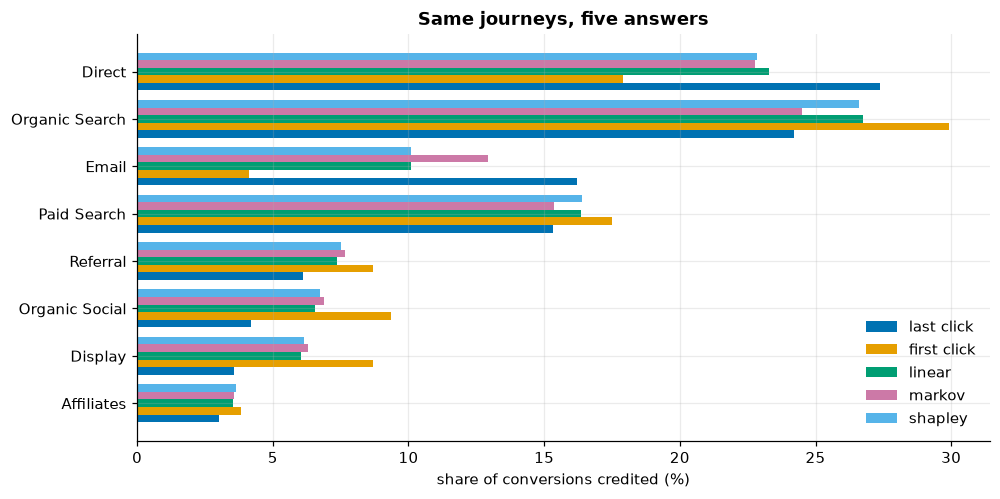

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order = share.sort_values("last_click").index
y = np.arange(len(order))
h = 0.16
for i, model in enumerate(core):
    ax.barh(y + i * h, share.loc[order, model] * 100, h, label=model.replace("_", " "), color=PALETTE[i])
ax.set_yticks(y + 2 * h, order)
ax.set_xlabel("share of conversions credited (%)")
ax.set_title("Same journeys, five answers")
ax.legend(loc="lower right")
save(fig, "03_attribution_models")

## Why the models disagree

### 1. Channels play different roles in a journey

In [6]:
profile = A.position_profile(paths)
profile

,first,middle,last,only,opener_ratio
Display,242.000,72.000,32.000,114.000,0.883
Organic Social,262.000,71.000,51.000,121.000,0.837
Referral,192.000,92.000,86.000,164.000,0.691
Affiliates,82.000,60.000,49.000,75.000,0.626
Organic Search,665.000,333.000,431.000,562.000,0.607
Paid Search,347.000,184.000,258.000,371.000,0.574
Direct,322.000,442.000,709.000,413.000,0.312
Email,79.000,231.000,575.000,90.000,0.121


In converting multi-touch journeys, when Display or Organic Social is the first or last touch, it
is the first touch 84-88% of the time. Email is the last touch 88% of the time and Direct 69%. So:

- **Last-click** gives everything to the closer and starves openers. Display looks worthless.
- **First-click** does the opposite: Email, which closes, looks small.
- **Linear** splits each journey evenly, so it lands in the middle by construction.

All three heuristics are *rules about position*. None of them look at non-converting journeys, so
none can tell whether a channel's presence changes the odds of converting.

*Ground truth check:* the generator draws first sessions from an acquisition mix heavy in Display
and Social and return sessions from a mix heavy in Direct and Email. The position profile and the
first-vs-last gap recover exactly that.

### 2. Markov uses the journeys that did not convert

In [7]:
re = A.removal_effects(paths).sort_values(ascending=False)
re.to_frame().assign(credit_share=re / re.sum())

,removal_effect,credit_share
Organic Search,0.396,0.245
Direct,0.368,0.228
Paid Search,0.248,0.154
Email,0.209,0.129
Referral,0.124,0.077
Organic Social,0.111,0.069
Display,0.102,0.063
Affiliates,0.058,0.036


A channel's removal effect is how much P(conversion) falls if every visit to it ended the journey.
Organic Search and Direct are on so many converting routes that removing either cuts conversions by
about 40%. The effects sum to well over 100% because routes overlap, so credit is the normalised
share. Markov sits close to linear here because most journeys are one or two touches. With longer
journeys and real channel interactions the two diverge more.

### 3. Shapley depends entirely on how you define a coalition's value

In [8]:
variants = A.shares(A.compare(paths, models={"shapley": A.shapley, "shapley_rate": A.shapley_rate,
                                             "linear": A.linear}))
variants

,shapley,shapley_rate,linear
channel,,,
Organic Search,0.266,0.117,0.268
Direct,0.229,0.314,0.233
Paid Search,0.164,0.177,0.164
Email,0.101,0.346,0.101
Referral,0.075,0.044,0.074
Organic Social,0.067,-0.039,0.066
Display,0.061,-0.051,0.060
Affiliates,0.036,0.093,0.035


- **Shapley, count game** (v(S) = conversions of journeys using only channels in S): every journey
  is a unanimity game, so the Shapley value is *exactly* an equal split over the journey's distinct
  channels. It equals linear except where a channel repeats in a path, which is why the two columns
  match to two decimals.
- **Shapley, rate game** (v(S) = conversion rate of those journeys): Display and Social go
  negative. Their journeys convert below average, so adding them lowers a coalition's rate. That
  answers "does this channel raise conversion rate?" rather than "how many conversions does it
  drive?". It's the wrong question for budget, because prospecting channels bring many
  low-intent users *by design*.

So "Shapley" isn't one answer. The characteristic function is a modelling choice and should be
stated alongside the result.

## How certain are the shares?

In [9]:
boot = A.bootstrap_shares(paths, A.markov, n_boot=200)
boot.sort_values("share", ascending=False)

,share,ci_low,ci_high
channel,,,
Organic Search,0.245,0.238,0.252
Direct,0.228,0.221,0.234
Paid Search,0.154,0.147,0.160
Email,0.129,0.123,0.135
Referral,0.077,0.072,0.082
Organic Social,0.069,0.065,0.072
Display,0.063,0.060,0.066
Affiliates,0.036,0.033,0.039


Bootstrap intervals are about ±0.5-1 percentage point, so the model-to-model gaps (Email: 4% to
16%) are far larger than the sampling noise. **The disagreement is about assumptions, not data.**

## Revenue view

In [10]:
A.shares(A.compare(paths, metric="revenue_usd", models=core))

,last_click,first_click,linear,markov,shapley
channel,,,,,
Organic Search,0.239,0.300,0.266,0.245,0.264
Direct,0.277,0.176,0.232,0.228,0.228
Paid Search,0.153,0.169,0.159,0.154,0.160
Email,0.158,0.040,0.100,0.129,0.100
Referral,0.060,0.084,0.072,0.077,0.073
Organic Social,0.046,0.101,0.071,0.069,0.073
Display,0.037,0.092,0.064,0.063,0.065
Affiliates,0.030,0.038,0.035,0.036,0.037


## What to tell the marketing team

1. **Don't cut Display or Organic Social on last-click numbers.** They mostly open journeys
   (first touch 84-88% of the time), so last-click credits them about 4% each against 6-9% under
   every model that sees the whole journey.
2. **Email's last-click credit (16%) overstates it,** because it mostly closes journeys other
   channels started. Markov puts it at 13%, linear at 10%.
3. **Use Markov as the default** for channel credit: it is the only model here that uses
   non-converting journeys and stays stable under resampling. Report last and first click beside it
   as bounds.
4. **None of these models are causal.** They split observed conversions; they don't say what would
   happen without a channel. Validate budget moves with a geo or holdout experiment before shifting
   spend.